In [2]:
import geopandas as gpd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point

In [3]:
# ----------------------------------------------------
# 1. VECTOR DATA (GeoPandas — R's 'sf' analogue)
# ----------------------------------------------------
# Define point locations (WGS 84 / EPSG:4326)
coords = [(-122.4194, 37.7749), (-122.4083, 37.7833), (-122.4312, 37.7650)]
geometry = [Point(xy) for xy in coords]
gdf = gpd.GeoDataFrame({"Station": ["A", "B", "C"], "geometry": geometry}, crs="EPSG:4326")

# Reproject CRS (sf: st_transform) -> UTM Zone 10N in meters
gdf_utm = gdf.to_crs(epsg=32610)

# 500m Metric Buffer (sf: st_buffer)
gdf_utm["buffer_500m"] = gdf_utm.buffer(500)

In [4]:
# ----------------------------------------------------
# 2. RASTER DATA (Xarray — R's 'terra' analogue)
# ----------------------------------------------------
# Create 2D spatial coordinate arrays
x = np.linspace(-122.45, -122.38, 100)
y = np.linspace(37.75, 37.80, 100)
xx, yy = np.meshgrid(x, y)

# Generate spectral bands as DataArrays
red = xr.DataArray(0.2 + 0.1 * np.sin(xx * 50), coords=[('y', y), ('x', x)])
nir = xr.DataArray(0.6 + 0.2 * np.sin(xx * 50), coords=[('y', y), ('x', x)])

# Map Algebra: NDVI Calculation (terra: (nir - red)/(nir + red))
ndvi = (nir - red) / (nir + red)

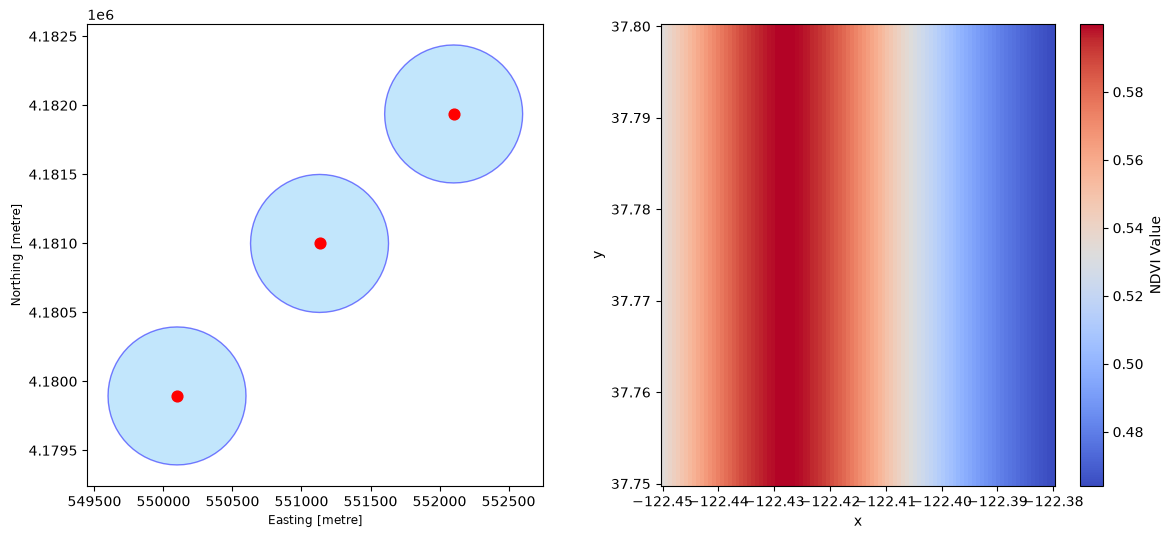

In [5]:
# ----------------------------------------------------
# 3. VISUALIZATION (Matplotlib)
# ----------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot vector buffers & points
buffers_gdf = gpd.GeoDataFrame(geometry=gdf_utm["buffer_500m"], crs=gdf_utm.crs)
buffers_gdf.plot(ax=ax1, color='lightskyblue', edgecolor='blue', alpha=0.5)
gdf_utm.plot(ax=ax1, color='red', marker='o', markersize=60)

# Plot raster grid using imshow
ndvi.plot.imshow(ax=ax2, cmap='coolwarm', cbar_kwargs={'label': 'NDVI Value'})
#plt.savefig('/workspace/scratch/python_geospatial_demo.png', dpi=150)

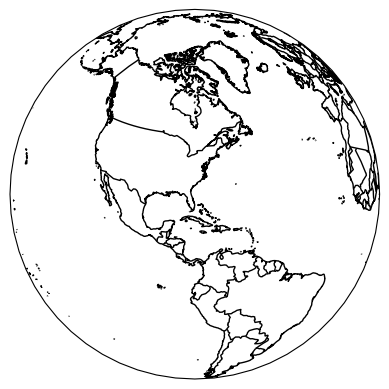

In [35]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.Orthographic(-80, 30)})
ax.coastlines(resolution='50m')
ax.add_feature(cfeature.BORDERS)
#ax.add_feature(cfeature.COASTLINE)

In [21]:
import xarray as xr

# Open NetCDF dataset directly from a URL
url = "http://psl.noaa.gov/thredds/dodsC/Datasets/noaa.oisst.v2.highres/sst.day.mean.2026.nc"
ds = xr.open_dataset(url, engine="netcdf4")
ds

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 312, lat: 720, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2026-01-01 2026-01-02 ... 2026-11-08
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    sst      (time, lat, lon) float32 1GB ...
Attributes:
    Conventions:                     CF-1.5
    _NCProperties:                   version=2,netcdf=4.7.0,hdf5=1.10.5,
    title:                           NOAA/NCEI 1/4 Degree Daily Optimum Inter...
    institution:                     NOAA/National Centers for Environmental ...
    source:                          NOAA/NCEI https://www.ncei.noaa.gov/data...
    References:                      https://www.psl.noaa.gov/data/gridded/da...
    dataset_title:                   NOAA Daily Optimum Interpolation Sea Sur...
    version:                         Version 2.1
    comment:                         Reynolds, et al.(2007) Daily High-Resolu...
    DODS_EXTRA.Unlimited_Dimension:  time

In [25]:
sst = ds['sst']
sst_subset = sst.sel(time='2026-11-08',
 lat=slice(17, 40),
  lon=slice(260, 290))

sst_subset = (
    sst_subset
    .assign_coords(lon=((sst_subset.lon + 180) % 360) - 180)
    .sortby("lon")
)

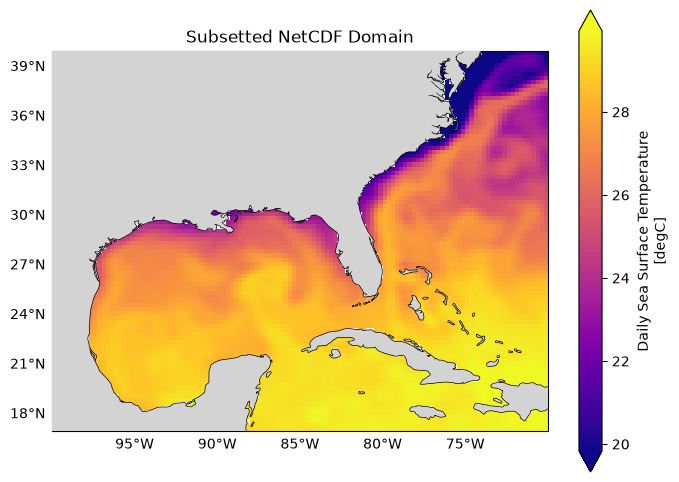

In [31]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter

proj = ccrs.PlateCarree()

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': proj})

# Render 2D grid image with colormap styling
sst_subset.plot.imshow(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='plasma',
    robust=True  # Automatically scales color limits to 2nd-98th percentiles
)
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0,
    color="none",
)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}

#ax.set_xticks([-180, -120, -60, 0, 60, 120, 180], crs=ccrs.PlateCarree())
#ax.set_yticks([-60, -30, 0, 30, 60], crs=ccrs.PlateCarree())
#ax.xaxis.set_major_formatter(LongitudeFormatter())
#ax.yaxis.set_major_formatter(LatitudeFormatter())
#ax.tick_params(
#    axis="both",
#    direction="out",
#    length=4,
#    width=0.8,
#)

ax.coastlines(resolution='50m', color='black', linewidth=1)
ax.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="none",
    zorder=3,
)
ax.set_aspect('equal')
ax.set_title("Subsetted NetCDF Domain")
plt.show()

In [12]:
sst_subset.coords

Coordinates:
  * lat      (lat) float32 368B 17.12 17.38 17.62 17.88 ... 39.38 39.62 39.88
  * lon      (lon) float32 480B 260.1 260.4 260.6 260.9 ... 289.4 289.6 289.9
    time     datetime64[ns] 8B 2026-01-01

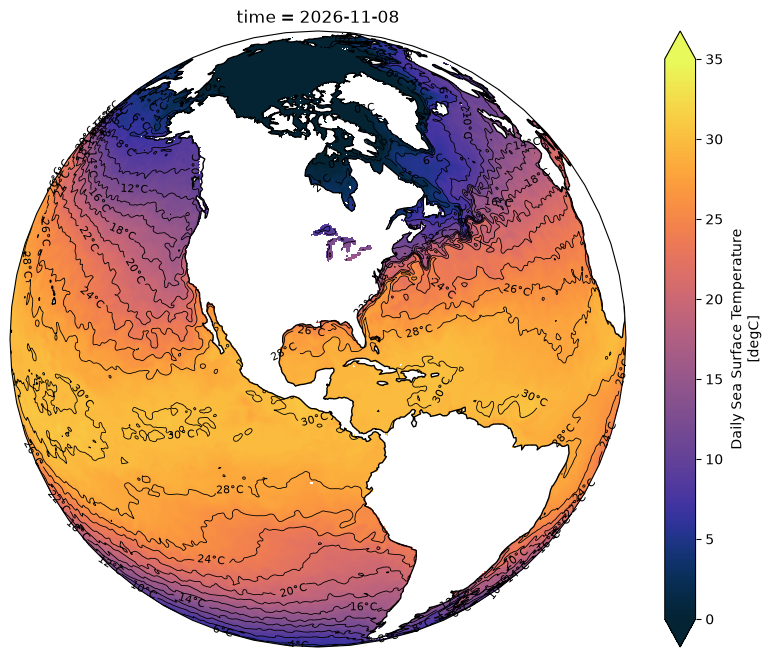

In [61]:
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np


sst_global = sst.sel(time='2026-11-08')

sst_global = (
    sst_global
    .assign_coords(lon=((sst_global.lon + 180) % 360) - 180)
    .sortby("lon")
)

fig, ax = plt.subplots(
    figsize=(10, 8),
    subplot_kw={"projection": ccrs.Orthographic(central_longitude=-90, central_latitude=27)},
)
#ax.coastlines(resolution='50m')
#ax.add_feature(cfeature.BORDERS)
#ax.add_feature(cfeature.COASTLINE)

sst_global.plot.pcolormesh(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.thermal,
    vmin=0,
    vmax=35,
    cbar_kwargs={"extend": "both"},
)

contours = sst_global.plot.contour(
    ax=ax,
    levels=np.arange(0, 36, 2),
    colors="black",
    linewidths=0.6,
    transform=ccrs.PlateCarree(),
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.0f°C")
ax.coastlines()
ax.set_global()

In [47]:
sst_subset.plot.pcolormesh?